In [1]:
import sys
from pathlib import Path

# Add project root to sys.path so we can import from utils
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from utils.plotting import PALETTE, plot_cdf, plot_pdf, set_style

# Apply standard style across all plots
set_style()

# Gamma Distribution: Modeling Multi-Stage Waiting Times & Skewed Processes

## 1. Intuition & Motivation

In the Exponential distribution, we asked: *"How long until the **first** event occurs?"*
The **Gamma distribution** generalizes this to continuous multi-event processes:
***"How long do I have to wait until $\alpha$ continuous events have occurred?"***

Just as the Negative Binomial generalizes the discrete Geometric distribution, the Gamma distribution generalizes the continuous Exponential distribution:
- Total time required for a patient to complete $\alpha$ sequential stages of medical treatment.
- Total rainfall volume accumulated during a prolonged storm.
- Aggregated server processing latency across multiple microservice network hops.
- Operational lifespan of a backup system equipped with $\alpha$ replacement components.

In addition, the Gamma distribution is the **conjugate prior** for the Poisson rate $\lambda$ in Bayesian statistics, and serves as the mother distribution of the **Chi-Square** distribution.

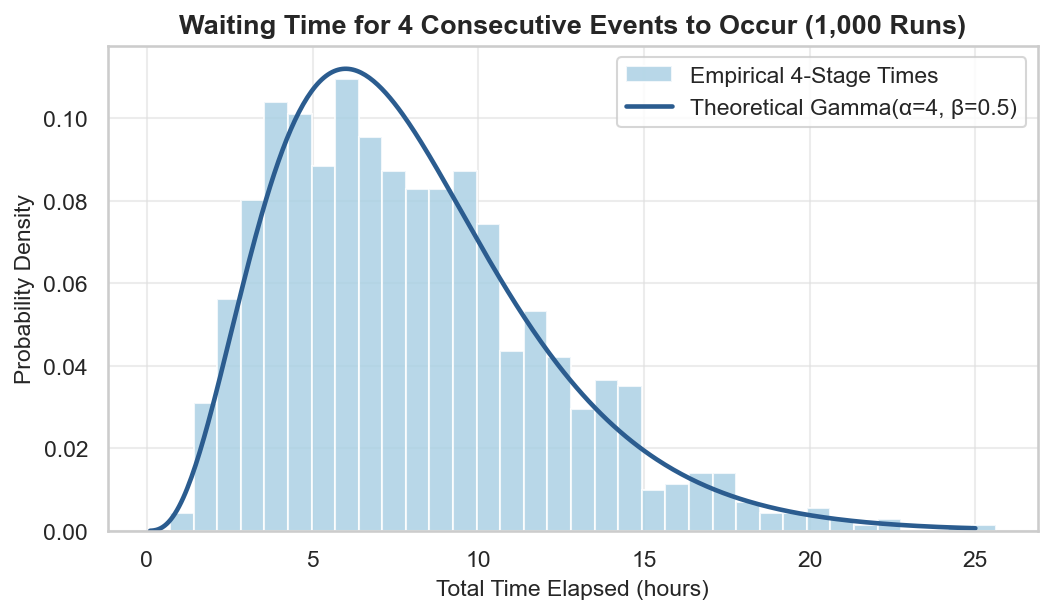

Sample Mean Total Time: 8.00 hrs (Theoretical α/β: 8.00 hrs)
Sample Variance:        16.74 hrs² (Theoretical α/β²: 16.00 hrs²)


In [2]:
# Parameters: Waiting for alpha = 4 events at rate beta = 0.5 events/hour
alpha_events = 4
beta_rate = 0.5
n_simulations = 1000

# Seed for reproducibility
rng = np.random.default_rng(seed=42)

# Generate 4 independent Exponential waiting times per experiment: Shape (1000, 4)
exponential_stages = rng.exponential(
    scale=1.0 / beta_rate, size=(n_simulations, alpha_events)
)

# Total time to complete all 4 stages: T = sum(X_i)
total_times = np.sum(exponential_stages, axis=1)

# Plot empirical waiting time distribution
plt.figure(figsize=(8, 4.2))
plt.hist(
    total_times,
    bins=35,
    density=True,
    color=PALETTE["fill"],
    edgecolor="white",
    alpha=0.8,
    label="Empirical 4-Stage Times",
)

# Overlay theoretical Gamma PDF
t_axis = np.linspace(0.1, 25, 400)
pdf_gamma_theory = stats.gamma.pdf(
    t_axis, a=alpha_events, scale=1.0 / beta_rate
)
plt.plot(
    t_axis,
    pdf_gamma_theory,
    color=PALETTE["primary"],
    linewidth=2.2,
    label=f"Theoretical Gamma(α={alpha_events}, β={beta_rate})",
)

plt.title(
    f"Waiting Time for {alpha_events} Consecutive Events to Occur (1,000 Runs)",
    weight="bold",
)
plt.xlabel("Total Time Elapsed (hours)")
plt.ylabel("Probability Density")
plt.legend(frameon=True)
plt.show()

print(f"Sample Mean Total Time: {np.mean(total_times):.2f} hrs (Theoretical α/β: {alpha_events/beta_rate:.2f} hrs)")
print(f"Sample Variance:        {np.var(total_times, ddof=1):.2f} hrs² (Theoretical α/β²: {alpha_events/(beta_rate**2):.2f} hrs²)")

## 2. Mathematical Definition

A continuous random variable $X$ follows a Gamma distribution, written:
$$X \sim \text{Gamma}(\alpha, \beta) \quad \text{or} \quad X \sim \text{Gamma}(k, \theta)$$

### Two Standard Parameterizations:
1. **Shape-Rate Parameterization ($\alpha, \beta$)**:
   - Shape $\alpha > 0$: number of events.
   - Rate $\beta > 0$: arrival rate per unit time.
   $$f(x) = \frac{\beta^\alpha}{\Gamma(\alpha)} x^{\alpha - 1} e^{-\beta x} \quad \text{for } x > 0$$

2. **Shape-Scale Parameterization ($k, \theta$)** — **(SciPy Default)**:
   - Shape $k = \alpha > 0$.
   - Scale $\theta = \frac{1}{\beta} > 0$: mean time per event.
   $$f(x) = \frac{1}{\Gamma(k)\theta^k} x^{k - 1} e^{-x / \theta} \quad \text{for } x > 0$$

### The Gamma Function $\Gamma(\alpha)$
The normalizing constant is the continuous extension of the factorial:
$$\Gamma(\alpha) = \int_{0}^{\infty} t^{\alpha - 1} e^{-t} \, dt$$
*(For positive integers, $\Gamma(n) = (n - 1)!$. For example, $\Gamma(4) = 3! = 6$.)*

### Cumulative Distribution Function (CDF)
$$F(x) = P(X \le x) = \frac{\gamma(\alpha, \beta x)}{\Gamma(\alpha)}$$
where $\gamma(s, x) = \int_0^x t^{s-1} e^{-t} dt$ is the lower incomplete gamma function.

### SciPy Parameterization Convention
In `scipy.stats.gamma(a, scale)`:
- `a = alpha` (the shape parameter)
- `scale = 1 / beta` (the scale parameter $\theta$)

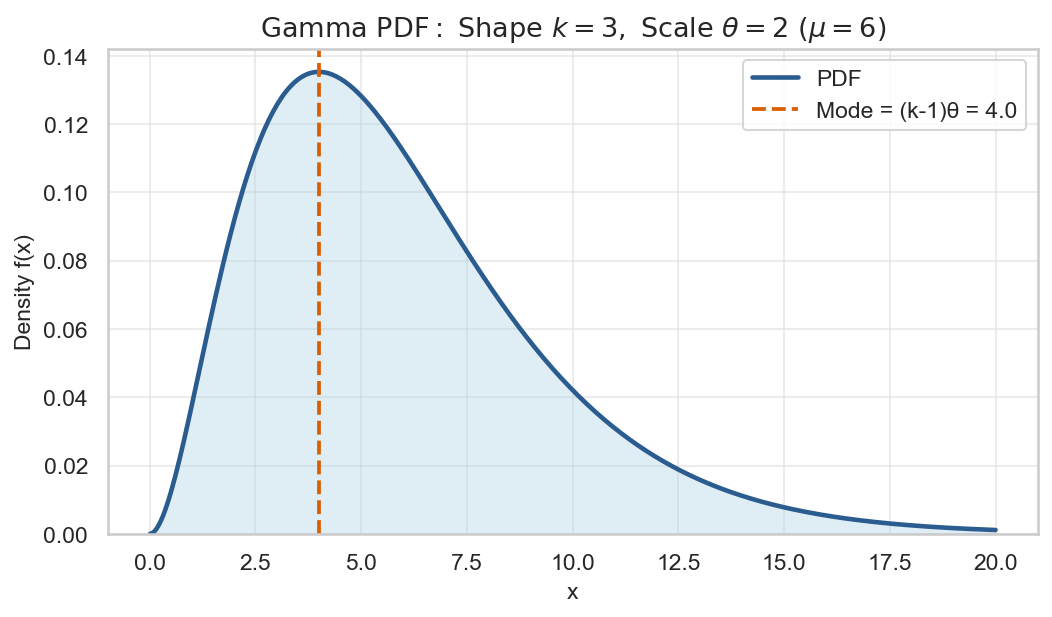

In [3]:
# Parameters: alpha = 3, theta = 2.0 (mean = alpha * theta = 6.0)
alpha_val = 3.0
theta_val = 2.0

x_eval = np.linspace(0.01, 20.0, 400)
pdf_vals = stats.gamma.pdf(x_eval, a=alpha_val, scale=theta_val)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_pdf(
    x_eval,
    pdf_vals,
    title=rf"$\mathrm{{Gamma\ PDF:\ Shape}}\ k={alpha_val:.0f},\ \mathrm{{Scale}}\ \theta={theta_val:.0f}\ (\mu={alpha_val * theta_val:.0f})$",
    xlabel="x",
    ylabel="Density f(x)",
    fill=True,
    ax=ax,
)

# Highlight peak (mode): (alpha - 1) * theta for alpha >= 1
mode_val = (alpha_val - 1.0) * theta_val
ax.axvline(
    mode_val,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=1.8,
    label=f"Mode = (k-1)θ = {mode_val:.1f}",
)
ax.legend(frameon=True)
plt.show()

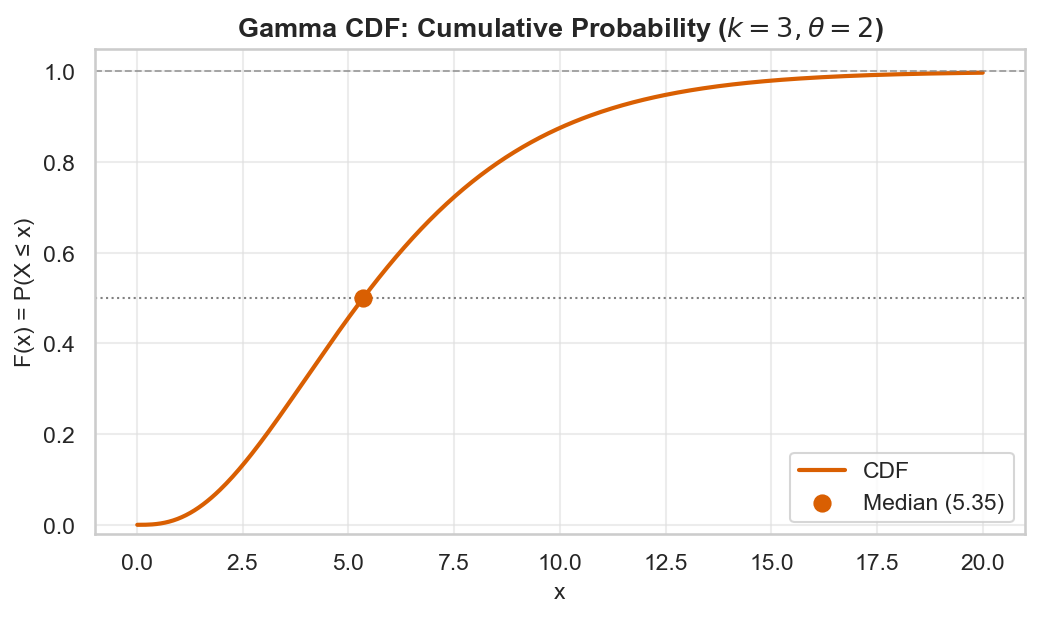

In [4]:
cdf_vals = stats.gamma.cdf(x_eval, a=alpha_val, scale=theta_val)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_cdf(
    x_eval,
    cdf_vals,
    is_discrete=False,
    title=f"Gamma CDF: Cumulative Probability ($k={alpha_val:.0f}, \\theta={theta_val:.0f}$)",
    xlabel="x",
    ylabel="F(x) = P(X ≤ x)",
    ax=ax,
)
ax.axhline(0.5, color="gray", linestyle=":", linewidth=1)
median_approx = stats.gamma.ppf(0.5, a=alpha_val, scale=theta_val)
ax.scatter([median_approx], [0.5], color=PALETTE["secondary"], s=60, zorder=5, label=f"Median ({median_approx:.2f})")
ax.legend(frameon=True)
plt.show()

## 3. Key Theoretical Properties

For $X \sim \text{Gamma}(\alpha, \beta)$ (or with scale $\theta = 1/\beta$):

### 1. Moments
- **Mean ($\mu$)**:
  $$\mu = \frac{\alpha}{\beta} = k\theta$$
- **Variance ($\sigma^2$)**:
  $$\sigma^2 = \frac{\alpha}{\beta^2} = k\theta^2$$
- **Standard Deviation ($\sigma$)**:
  $$\sigma = \frac{\sqrt{\alpha}}{\beta} = \sqrt{k}\theta$$

### 2. Skewness ($\gamma_1$)
$$\gamma_1 = \frac{2}{\sqrt{\alpha}} = \frac{2}{\sqrt{k}}$$
- Always positive ($\gamma_1 > 0$), meaning right-skewed.
- Notice skewness depends **only on the shape parameter $\alpha$**, independent of scale $\theta$!
- As $\alpha \to \infty$, $\gamma_1 \to 0$ (the distribution converges to a symmetric Normal distribution).

### 3. Excess Kurtosis ($\gamma_2$)
$$\gamma_2 = \frac{6}{\alpha} = \frac{6}{k}$$
Decays towards $0$ as $\alpha \to \infty$.

### 4. Mode
$$\text{Mode} = \frac{\alpha - 1}{\beta} = (k - 1)\theta \quad \text{for } \alpha \ge 1$$
*(When $\alpha < 1$, the density approaches $\infty$ at $x = 0$, so the mode is $0$).*

In [5]:
# Verify analytical moments against SciPy
a_test = 4.0
theta_test = 2.5  # beta = 0.4

mu_form = a_test * theta_test
var_form = a_test * (theta_test**2)
std_form = np.sqrt(var_form)
skew_form = 2.0 / np.sqrt(a_test)
kurt_form = 6.0 / a_test

mu_sp, var_sp, skew_sp, kurt_sp = stats.gamma.stats(
    a=a_test, scale=theta_test, moments="mvsk"
)

print("--- GAMMA THEORETICAL MOMENTS ---")
print(f"Moment               | Analytical | SciPy")
print("-" * 46)
print(f"Mean (μ = kθ)        | {mu_form:10.4f} | {float(mu_sp):10.4f}")
print(f"Variance (σ² = kθ²)  | {var_form:10.4f} | {float(var_sp):10.4f}")
print(f"Std Deviation (σ)    | {std_form:10.4f} | {np.sqrt(float(var_sp)):10.4f}")
print(f"Skewness (γ₁)        | {skew_form:10.4f} | {float(skew_sp):10.4f}")
print(f"Excess Kurtosis (γ₂) | {kurt_form:10.4f} | {float(kurt_sp):10.4f}")

--- GAMMA THEORETICAL MOMENTS ---
Moment               | Analytical | SciPy
----------------------------------------------
Mean (μ = kθ)        |    10.0000 |    10.0000
Variance (σ² = kθ²)  |    25.0000 |    25.0000
Std Deviation (σ)    |     5.0000 |     5.0000
Skewness (γ₁)        |     1.0000 |     1.0000
Excess Kurtosis (γ₂) |     1.5000 |     1.5000


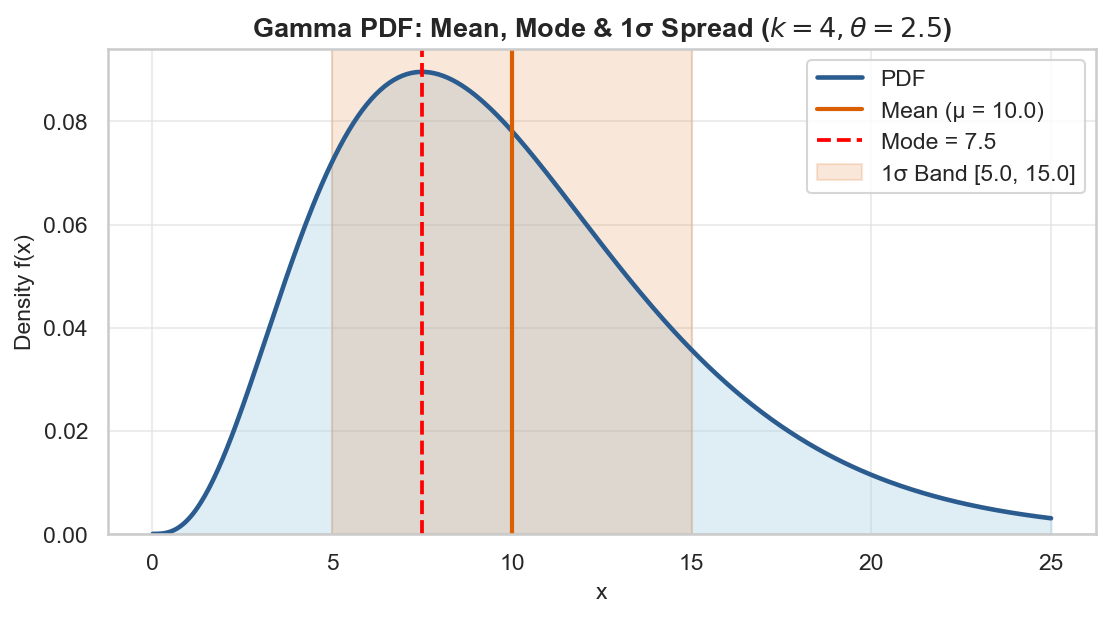

In [6]:
x_span = np.linspace(0.01, 25.0, 400)
pdf_span = stats.gamma.pdf(x_span, a=a_test, scale=theta_test)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
plot_pdf(
    x_span,
    pdf_span,
    title=f"Gamma PDF: Mean, Mode & 1σ Spread ($k={a_test:.0f}, \\theta={theta_test:.1f}$)",
    xlabel="x",
    ylabel="Density f(x)",
    fill=True,
    ax=ax,
)

# Mean and Mode markers
ax.axvline(
    mu_form,
    color=PALETTE["secondary"],
    linestyle="-",
    linewidth=2,
    label=f"Mean (μ = {mu_form:.1f})",
)
mode_calc = (a_test - 1.0) * theta_test
ax.axvline(
    mode_calc,
    color="red",
    linestyle="--",
    linewidth=1.8,
    label=f"Mode = {mode_calc:.1f}",
)

# 1-Sigma Band
ax.axvspan(
    max(0, mu_form - std_form),
    mu_form + std_form,
    color=PALETTE["secondary"],
    alpha=0.15,
    label=f"1σ Band [{max(0, mu_form - std_form):.1f}, {mu_form + std_form:.1f}]",
)

ax.legend(frameon=True)
plt.show()

## 4. Parameter Variation

The Gamma distribution demonstrates exceptional versatility because its shape can transform completely:

### 1. Effect of Shape Parameter $k = \alpha$:
- **$\alpha < 1$ (e.g., $\alpha = 0.5$)**: Strictly decreasing L-shaped curve; diverges to $\infty$ at $x = 0$.
- **$\alpha = 1$**: Exactly the **Exponential distribution**!
- **$\alpha = 2$ to $5$**: Classic right-skewed unimodal hump with a peak at $(\alpha - 1)\theta$.
- **$\alpha \ge 10$**: By the Central Limit Theorem, the curve approaches a symmetric Gaussian bell shape.

### 2. Effect of Scale Parameter $\theta = 1/\beta$:
- Acts as a pure stretching factor along the x-axis, scaling both the mean ($\mu = k\theta$) and standard deviation ($\sigma = \sqrt{k}\theta$) proportionally.

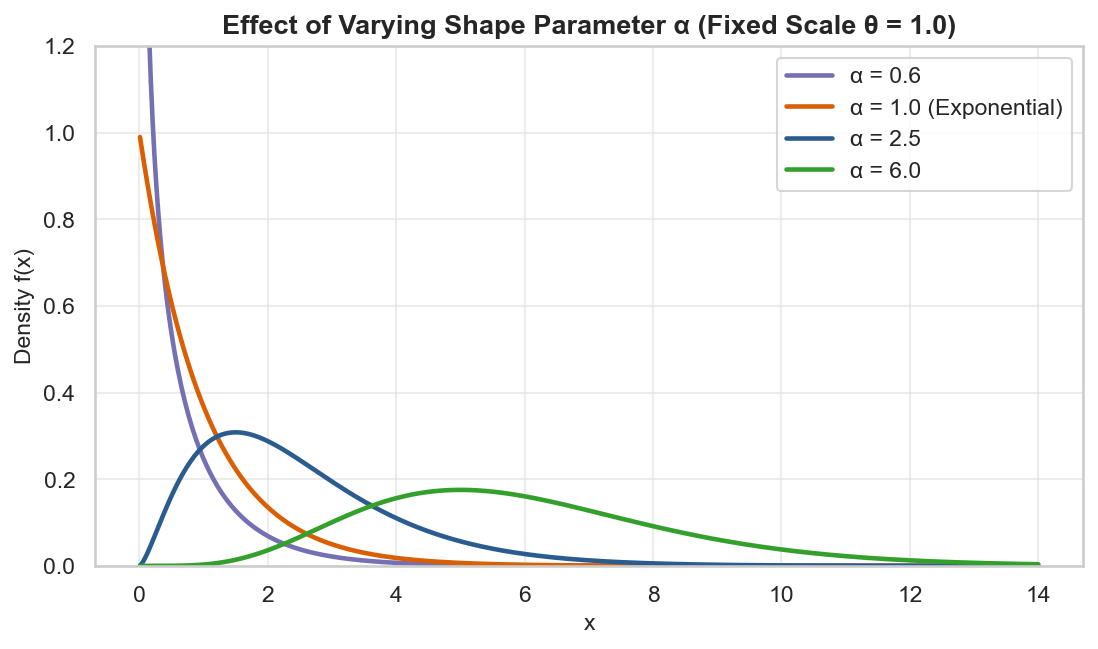

In [7]:
shapes = [0.6, 1.0, 2.5, 6.0]
colors = [PALETTE["accent"], PALETTE["secondary"], PALETTE["primary"], "#33a02c"]
x_eval_shape = np.linspace(0.01, 14.0, 500)

fig, ax = plt.subplots(figsize=(8.5, 4.5))

for a_val, col in zip(shapes, colors):
    pdf = stats.gamma.pdf(x_eval_shape, a=a_val, scale=1.0)
    lbl = f"α = {a_val} (Exponential)" if a_val == 1.0 else f"α = {a_val}"
    ax.plot(x_eval_shape, pdf, color=col, linewidth=2.2, label=lbl)

ax.set_title("Effect of Varying Shape Parameter α (Fixed Scale θ = 1.0)", weight="bold")
ax.set_xlabel("x")
ax.set_ylabel("Density f(x)")
ax.set_ylim(0, 1.2)
ax.legend(frameon=True)
plt.show()

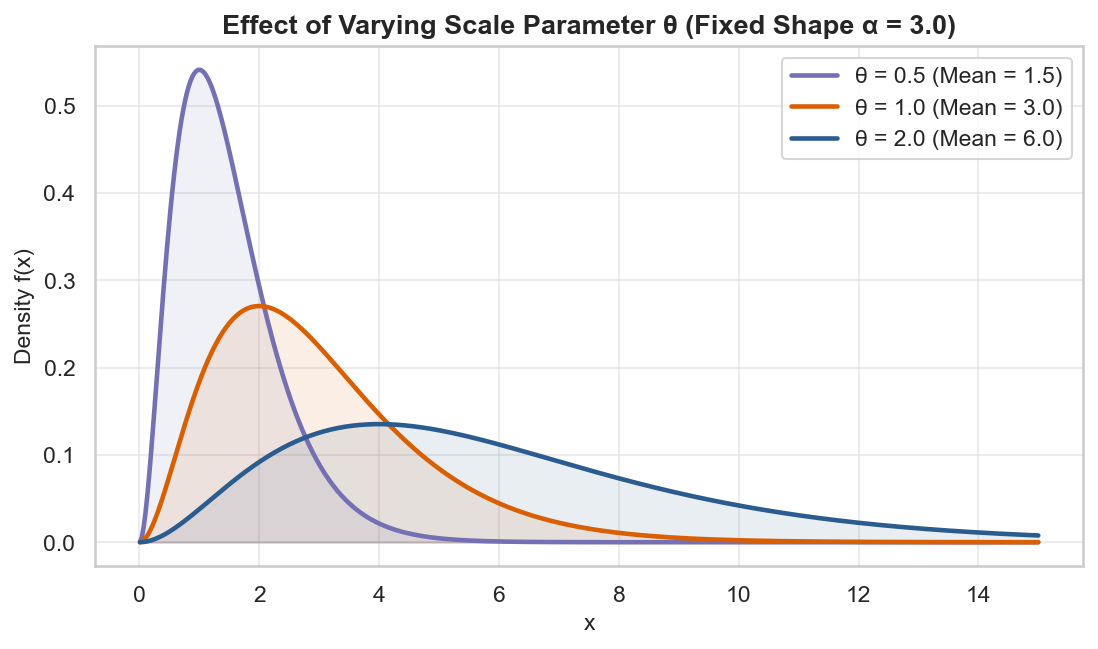

In [8]:
scales = [0.5, 1.0, 2.0]
a_fixed = 3.0
x_eval_scale = np.linspace(0.01, 15.0, 500)

fig, ax = plt.subplots(figsize=(8.5, 4.5))

for s_val, col in zip(scales, colors[:3]):
    pdf = stats.gamma.pdf(x_eval_scale, a=a_fixed, scale=s_val)
    ax.plot(
        x_eval_scale,
        pdf,
        color=col,
        linewidth=2.2,
        label=f"θ = {s_val:.1f} (Mean = {a_fixed * s_val:.1f})",
    )
    ax.fill_between(x_eval_scale, pdf, color=col, alpha=0.1)

ax.set_title(f"Effect of Varying Scale Parameter θ (Fixed Shape α = {a_fixed})", weight="bold")
ax.set_xlabel("x")
ax.set_ylabel("Density f(x)")
ax.legend(frameon=True)
plt.show()

## 5. Simulation & Law of Large Numbers

Generating random variates from $\text{Gamma}(\alpha, \theta)$ uses the **Marsaglia-Tsang method** (fast rejection sampling from a Gaussian transformed proposal).

By the **Law of Large Numbers**:
$$\bar{X}_N = \frac{1}{N}\sum_{i=1}^N X_i \xrightarrow{P} \mu = \alpha \theta$$
$$s_N^2 = \frac{1}{N-1}\sum_{i=1}^N (X_i - \bar{X}_N)^2 \xrightarrow{P} \sigma^2 = \alpha \theta^2$$

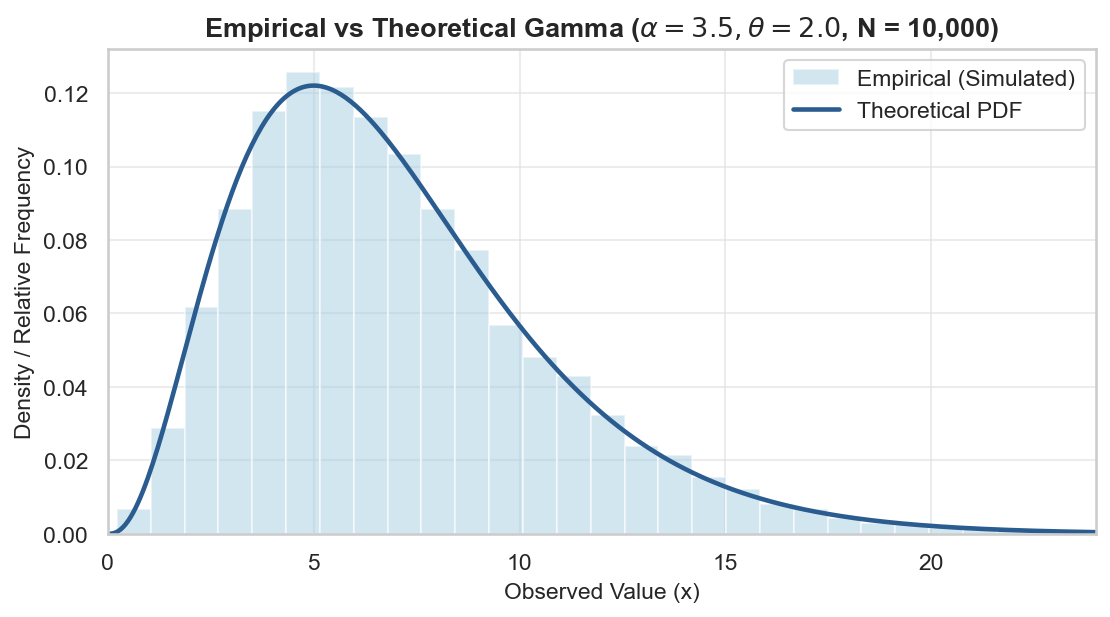

In [9]:
from utils.plotting import plot_sample_vs_theory

a_sim = 3.5
theta_sim = 2.0
sample_size = 10000

mu_target = a_sim * theta_sim  # 7.0
var_target = a_sim * (theta_sim**2)  # 14.0

# Generate random Gamma variates
samples_gamma = stats.gamma.rvs(
    a=a_sim, scale=theta_sim, size=sample_size, random_state=42
)

# Theoretical curve
x_th = np.linspace(0.01, 24.0, 400)
pdf_th = stats.gamma.pdf(x_th, a=a_sim, scale=theta_sim)

# Plot empirical histogram vs continuous PDF
fig, ax = plt.subplots(figsize=(8.5, 4.2))
plot_sample_vs_theory(
    samples=samples_gamma,
    x_theory=x_th,
    y_theory=pdf_th,
    is_discrete=False,
    title = rf"Empirical vs Theoretical Gamma ($\alpha = {a_sim}, \theta = {theta_sim}$, N = {sample_size:,})",
    xlabel="Observed Value (x)",
    ax=ax,
)
ax.set_xlim(0, 24)
plt.show()

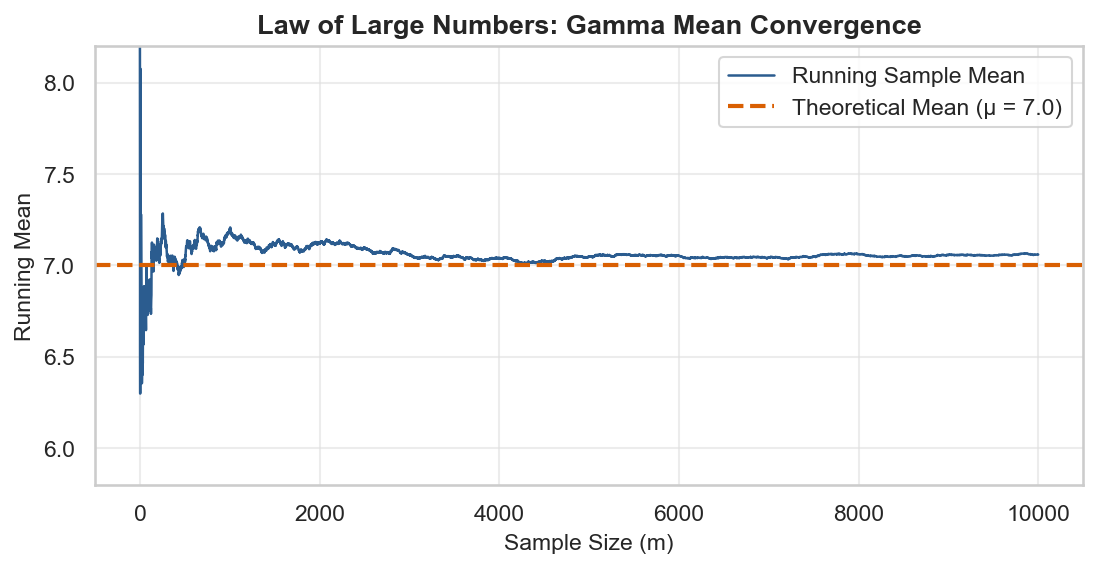

Sample Mean: 7.0594 (Theoretical: 7.0000)
Sample Var:  13.7572 (Theoretical: 14.0000)


In [10]:
# Running average convergence
running_gamma_mean = np.cumsum(samples_gamma) / np.arange(1, sample_size + 1)
plt.figure(figsize=(8.5, 3.8))
plt.plot(
    running_gamma_mean,
    color=PALETTE["primary"],
    linewidth=1.2,
    label="Running Sample Mean",
)
plt.axhline(
    mu_target,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Theoretical Mean (μ = {mu_target:.1f})",
)
plt.title("Law of Large Numbers: Gamma Mean Convergence")
plt.xlabel("Sample Size (m)")
plt.ylabel("Running Mean")
plt.ylim(mu_target - 1.2, mu_target + 1.2)
plt.legend(frameon=True)
plt.show()

print(f"Sample Mean: {np.mean(samples_gamma):.4f} (Theoretical: {mu_target:.4f})")
print(f"Sample Var:  {np.var(samples_gamma, ddof=1):.4f} (Theoretical: {var_target:.4f})")

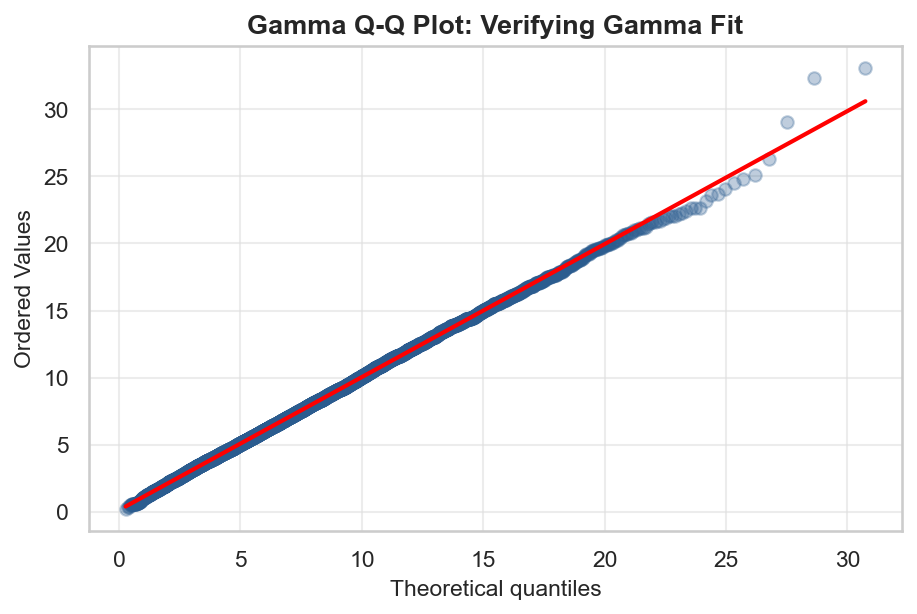

In [11]:
# Gamma Q-Q Plot Diagnostic
fig, ax = plt.subplots(figsize=(7, 4.2))
stats.probplot(samples_gamma, dist=stats.gamma(a=a_sim, scale=theta_sim), plot=ax)

# Style Q-Q plot
ax.get_lines()[0].set_markerfacecolor(PALETTE["primary"])
ax.get_lines()[0].set_color(PALETTE["primary"])
ax.get_lines()[0].set_alpha(0.3)
ax.get_lines()[1].set_color("red")
ax.get_lines()[1].set_linewidth(2)

ax.set_title("Gamma Q-Q Plot: Verifying Gamma Fit", weight="bold")
plt.show()

## 6. Applied Real-World Use Case: Hospital ICU Length of Stay (LOS)

### Scenario
Hospital administrators track the Length of Stay (LOS) in days for patients admitted to the Intensive Care Unit (ICU).
Because recovery involves sequential multi-stage healing (admission, stabilization, medical intervention, post-acute monitoring), LOS follows a Gamma distribution:
$$X \sim \text{Gamma}(\text{shape } k = 3.5, \, \text{scale } \theta = 2.0 \text{ days})$$

- Expected Stay: $\mu = k\theta = 3.5 \times 2.0 = \mathbf{7.0 \text{ days}}$
- Variance: $\sigma^2 = k\theta^2 = 3.5 \times 4.0 = 14.0 \text{ days}^2$ ($\sigma \approx 3.74$ days)

### Operations Questions:
1. **Short-stay discharges**: What percentage of patients are discharged within $5$ days?
2. **Extended stay outliers**: What percentage of patients experience prolonged stays $> 12$ days (requiring step-down bed reservation)?
3. **Capacity buffer**: How many bed-days must be budgeted to ensure $95\%$ of patients complete their stay without bed shortages?

In [12]:
k_icu = 3.5
theta_icu = 2.0

# 1. Discharged within 5 days: F(5)
prob_within_5 = stats.gamma.cdf(5.0, a=k_icu, scale=theta_icu)

# 2. Prolonged stay > 12 days: S(12)
prob_over_12 = stats.gamma.sf(12.0, a=k_icu, scale=theta_icu)

# 3. 95th percentile stay for bed capacity planning: Q(0.95)
p95_stay = stats.gamma.ppf(0.95, a=k_icu, scale=theta_icu)

print("--- HOSPITAL ICU CAPACITY PLANNING REPORT ---")
print(f"Mean Patient Stay (μ):       {k_icu * theta_icu:.1f} days")
print(f"Std Deviation (σ):          {np.sqrt(k_icu * theta_icu**2):.2f} days\n")
print(f"P(Discharge <= 5 days):     {prob_within_5 * 100:.2f}%")
print(f"P(Prolonged Stay > 12 days): {prob_over_12 * 100:.2f}%")
print(f"95th Percentile Bed Budget: {p95_stay:.2f} days")

--- HOSPITAL ICU CAPACITY PLANNING REPORT ---
Mean Patient Stay (μ):       7.0 days
Std Deviation (σ):          3.74 days

P(Discharge <= 5 days):     34.00%
P(Prolonged Stay > 12 days): 10.06%
95th Percentile Bed Budget: 14.07 days


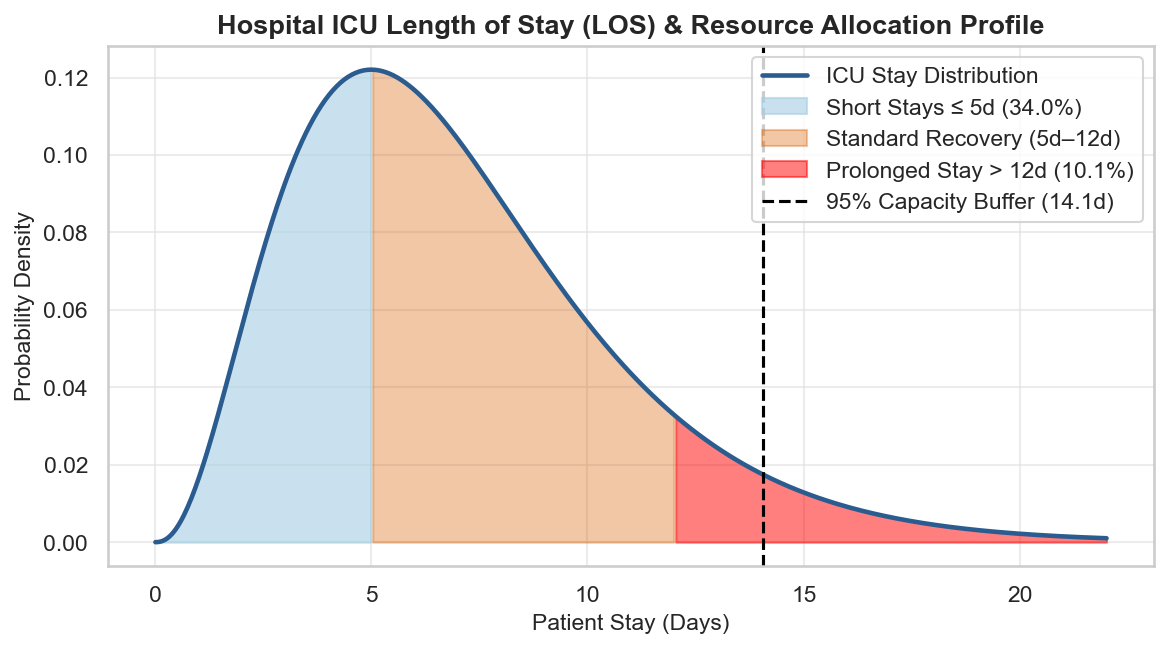

In [13]:
days = np.linspace(0.01, 22.0, 500)
pdf_icu = stats.gamma.pdf(days, a=k_icu, scale=theta_icu)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(days, pdf_icu, color=PALETTE["primary"], linewidth=2.2, label="ICU Stay Distribution")

# Zone 1: Routine stay (<= 5 days)
mask_short = days <= 5.0
ax.fill_between(days[mask_short], pdf_icu[mask_short], color=PALETTE["fill"], alpha=0.6, label=f"Short Stays ≤ 5d ({prob_within_5*100:.1f}%)")

# Zone 2: Moderate stay (5d to 12d)
mask_mid = (days > 5.0) & (days <= 12.0)
ax.fill_between(days[mask_mid], pdf_icu[mask_mid], color=PALETTE["secondary"], alpha=0.35, label="Standard Recovery (5d–12d)")

# Zone 3: Prolonged stay (> 12 days)
mask_long = days > 12.0
ax.fill_between(days[mask_long], pdf_icu[mask_long], color="red", alpha=0.5, label=f"Prolonged Stay > 12d ({prob_over_12*100:.1f}%)")

# 95th percentile planning line
ax.axvline(p95_stay, color="black", linestyle="--", linewidth=1.5, label=f"95% Capacity Buffer ({p95_stay:.1f}d)")

ax.set_title("Hospital ICU Length of Stay (LOS) & Resource Allocation Profile", weight="bold")
ax.set_xlabel("Patient Stay (Days)")
ax.set_ylabel("Probability Density")
ax.legend(frameon=True)
plt.show()

## 7. Parameter Estimation (Maximum Likelihood Estimation - MLE)

Given continuous observations $x_1, x_2, \dots, x_N$:

### The Log-Likelihood Function
$$\ln L(\alpha, \beta) = N \alpha \ln(\beta) - N \ln \Gamma(\alpha) + (\alpha - 1)\sum_{i=1}^{N}\ln(x_i) - \beta \sum_{i=1}^{N} x_i$$

### Solving for Rate $\beta$ (Given Shape $\alpha$):
Setting $\frac{\partial \ln L}{\partial \beta} = 0$:
$$\frac{N \alpha}{\beta} - \sum_{i=1}^N x_i = 0 \implies \hat{\beta}(\alpha) = \frac{\alpha}{\bar{x}}$$

### Digamma Equation for Shape $\alpha$:
Substituting $\hat{\beta}(\alpha)$ into $\frac{\partial \ln L}{\partial \alpha} = 0$:
$$\ln(\alpha) - \psi(\alpha) = \ln(\bar{x}) - \frac{1}{N}\sum_{i=1}^N \ln(x_i)$$
where $\psi(\alpha) = \frac{d}{d\alpha}\ln\Gamma(\alpha)$ is the **digamma function**.
This equation has no closed-form algebraic solution and is solved numerically.

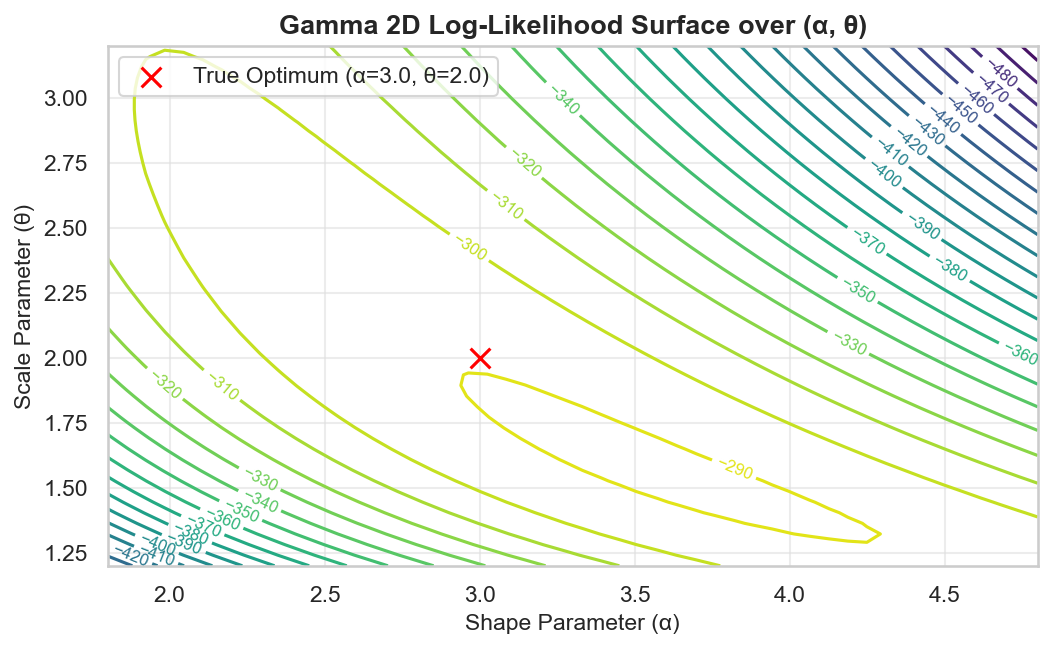

In [14]:
# True parameters
alpha_true = 3.0
theta_true = 2.0
N_obs = 120

# Generate synthetic observations
data_gamma = stats.gamma.rvs(
    a=alpha_true, scale=theta_true, size=N_obs, random_state=99
)

# 2D Grid search for visualization
a_grid = np.linspace(1.8, 4.8, 50)
th_grid = np.linspace(1.2, 3.2, 50)
A_mesh, Th_mesh = np.meshgrid(a_grid, th_grid)


def gamma_2d_log_lik(a_val, th_val, data):
    return np.sum(stats.gamma.logpdf(data, a=a_val, scale=th_val))


log_lik_map = np.zeros_like(A_mesh)
for i in range(A_mesh.shape[0]):
    for j in range(A_mesh.shape[1]):
        log_lik_map[i, j] = gamma_2d_log_lik(
            A_mesh[i, j], Th_mesh[i, j], data_gamma
        )

plt.figure(figsize=(8, 4.5))
contours = plt.contour(
    A_mesh, Th_mesh, log_lik_map, levels=25, cmap="viridis"
)
plt.clabel(contours, inline=True, fontsize=8)
plt.scatter(
    [alpha_true],
    [theta_true],
    color="red",
    s=90,
    zorder=5,
    marker="x",
    label=f"True Optimum (α={alpha_true}, θ={theta_true})",
)

plt.title("Gamma 2D Log-Likelihood Surface over (α, θ)", weight="bold")
plt.xlabel("Shape Parameter (α)")
plt.ylabel("Scale Parameter (θ)")
plt.legend(frameon=True)
plt.show()

In [15]:
from scipy.optimize import minimize


# Negative Log-Likelihood objective
def neg_log_lik_gamma(params, data):
    a_param, th_param = params
    if a_param <= 0.05 or th_param <= 0.05:
        return 1e9
    return -np.sum(stats.gamma.logpdf(data, a=a_param, scale=th_param))


# Method of Moments initial guess
x_bar = np.mean(data_gamma)
s_sq = np.var(data_gamma, ddof=1)
th_init = s_sq / x_bar
a_init = x_bar / th_init

# Optimize
res = minimize(
    neg_log_lik_gamma,
    x0=[a_init, th_init],
    args=(data_gamma,),
    bounds=[(0.1, 50.0), (0.1, 50.0)],
)
a_mle, th_mle = res.x

print("--- GAMMA MLE ESTIMATION RESULTS ---")
print(f"Sample Size (N):            {N_obs}")
print(f"Sample Mean:                {x_bar:.3f}")
print(f"Sample Variance:            {s_sq:.3f}\n")
print(f"Parameter | True Value | MLE Estimate")
print("-" * 38)
print(f"Shape (α) | {alpha_true:10.4f} | {a_mle:10.4f}")
print(f"Scale (θ) | {theta_true:10.4f} | {th_mle:10.4f}")
print(
    f"\nEstimated Model Mean:  {a_mle * th_mle:.3f} (matches sample mean {x_bar:.3f})"
)
from scipy.optimize import minimize


# Negative Log-Likelihood objective
def neg_log_lik_gamma(params, data):
    a_param, th_param = params
    if a_param <= 0.05 or th_param <= 0.05:
        return 1e9
    return -np.sum(stats.gamma.logpdf(data, a=a_param, scale=th_param))


# Method of Moments initial guess
x_bar = np.mean(data_gamma)
s_sq = np.var(data_gamma, ddof=1)
th_init = s_sq / x_bar
a_init = x_bar / th_init

# Optimize
res = minimize(
    neg_log_lik_gamma,
    x0=[a_init, th_init],
    args=(data_gamma,),
    bounds=[(0.1, 50.0), (0.1, 50.0)],
)
a_mle, th_mle = res.x

print("--- GAMMA MLE ESTIMATION RESULTS ---")
print(f"Sample Size (N):            {N_obs}")
print(f"Sample Mean:                {x_bar:.3f}")
print(f"Sample Variance:            {s_sq:.3f}\n")
print(f"Parameter | True Value | MLE Estimate")
print("-" * 38)
print(f"Shape (α) | {alpha_true:10.4f} | {a_mle:10.4f}")
print(f"Scale (θ) | {theta_true:10.4f} | {th_mle:10.4f}")
print(
    f"\nEstimated Model Mean:  {a_mle * th_mle:.3f} (matches sample mean {x_bar:.3f})"
)

--- GAMMA MLE ESTIMATION RESULTS ---
Sample Size (N):            120
Sample Mean:                5.609
Sample Variance:            8.507

Parameter | True Value | MLE Estimate
--------------------------------------
Shape (α) |     3.0000 |     3.5738
Scale (θ) |     2.0000 |     1.5695

Estimated Model Mean:  5.609 (matches sample mean 5.609)
--- GAMMA MLE ESTIMATION RESULTS ---
Sample Size (N):            120
Sample Mean:                5.609
Sample Variance:            8.507

Parameter | True Value | MLE Estimate
--------------------------------------
Shape (α) |     3.0000 |     3.5738
Scale (θ) |     2.0000 |     1.5695

Estimated Model Mean:  5.609 (matches sample mean 5.609)


## 8. Related Distributions & Summary

The Gamma distribution connects directly to the major families of continuous statistics:

1. **Exponential Distribution ($\alpha = 1$)**:
   - $\text{Gamma}(1, \theta) \equiv \text{Exponential}(\text{scale}=\theta)$.
   - A Gamma variable is the sum of $\alpha$ independent Exponentials.
2. **Chi-Square Distribution ($\chi^2_k$)**:
   - The Chi-Square distribution with $k$ degrees of freedom is a special case of the Gamma distribution:
     $$\chi^2_k \equiv \text{Gamma}\left(\alpha = \frac{k}{2}, \, \theta = 2\right)$$
3. **Beta Distribution (Ratio of Gammas)**:
   - If $X_1 \sim \text{Gamma}(\alpha, 1)$ and $X_2 \sim \text{Gamma}(\beta, 1)$ are independent:
     $$\frac{X_1}{X_1 + X_2} \sim \text{Beta}(\alpha, \beta)$$
4. **Poisson Conjugate Prior**:
   - In Bayesian inference, the Gamma distribution is the conjugate prior for a Poisson rate parameter $\lambda$.
5. **Gaussian Limit**:
   - As shape $\alpha \to \infty$, by the Central Limit Theorem, $\text{Gamma}(\alpha, \theta) \to \mathcal{N}(\alpha\theta, \alpha\theta^2)$.

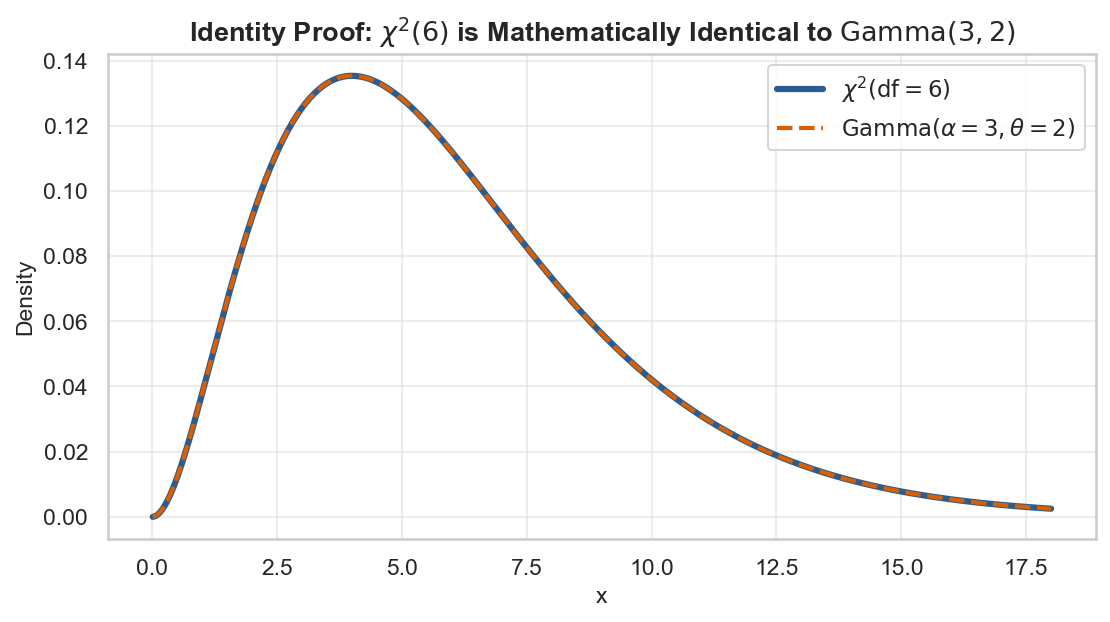

Max absolute difference between Chi-Square and Gamma: 5.55e-17


In [16]:
# Proving Chi-Square(df = 6) is identical to Gamma(alpha = 3, theta = 2)
df = 6
x_chi = np.linspace(0.01, 18.0, 400)

pdf_chi2 = stats.chi2.pdf(x_chi, df=df)
pdf_gamma_equiv = stats.gamma.pdf(x_chi, a=df / 2.0, scale=2.0)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(
    x_chi,
    pdf_chi2,
    color=PALETTE["primary"],
    linewidth=3.0,
    label=rf"$\chi^2(\text{{df}} = {df})$",
)
ax.plot(
    x_chi,
    pdf_gamma_equiv,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2.0,
    label=rf"$\mathrm{{Gamma}}(\alpha = {df/2:.0f}, \theta = 2)$",
)

ax.set_title(
    rf"Identity Proof: $\chi^2({df})$ is Mathematically Identical to $\text{{Gamma}}(3, 2)$",
    weight="bold",
)
ax.set_xlabel("x")
ax.set_ylabel("Density")
ax.legend(frameon=True)
plt.show()

print(f"Max absolute difference between Chi-Square and Gamma: {np.max(np.abs(pdf_chi2 - pdf_gamma_equiv)):.2e}")

### Summary Card: Gamma Distribution

| Property | Formulation (Shape-Scale Convention, $k, \theta$) |
| :--- | :--- |
| **Notation** | $X \sim \text{Gamma}(k, \theta)$ or $\text{Gamma}(\alpha, \beta)$ |
| **Parameters** | Shape $k = \alpha > 0$, Scale $\theta = 1/\beta > 0$ |
| **Support** | $x \in (0, \infty)$ |
| **PDF** | $f(x) = \frac{1}{\Gamma(k)\theta^k} x^{k-1} e^{-x/\theta}$ |
| **CDF** | $F(x) = \frac{\gamma(k, x/\theta)}{\Gamma(k)}$ (Regularized Incomplete Gamma) |
| **Mean ($\mu$)** | $k\theta = \frac{\alpha}{\beta}$ |
| **Variance ($\sigma^2$)** | $k\theta^2 = \frac{\alpha}{\beta^2}$ |
| **Skewness ($\gamma_1$)** | $\frac{2}{\sqrt{k}} = \frac{2}{\sqrt{\alpha}}$ |
| **Excess Kurtosis ($\gamma_2$)** | $\frac{6}{k} = \frac{6}{\alpha}$ |
| **Mode** | $(k - 1)\theta$ for $k \ge 1$ ($0$ if $k < 1$) |
| **Special Cases** | $k = 1 \implies \text{Exponential}$; $k = \nu/2, \theta = 2 \implies \chi^2_\nu$ |
| **Key Use Cases** | Multi-stage hospital length of stay, accumulated rainfall, queuing networks, Bayesian priors |